# Perfect magnetic conductor (PMC) boundaries

## Goal
Create a magnetic-wall cavity with `bz.PMC()` using **40 × 12 cells and 64 timesteps**.
The electric field has antinodes at the walls. Compare it with the exact discrete
Yee standing-wave mode, including boundary nodes.

PMC sets tangential H to zero at the physical wall. Yee magnetic samples sit half
a cell inside, so BeamZ uses opposite-sign exterior images. See the
[PMC formulation](https://warpx.readthedocs.io/en/26.03/theory/boundary_conditions.html#perfect-magnetic-conductor).
The 2D demo uses JAX; the optional 3D check below also supports CUDA.

## Setup
Run in the BeamZ development environment (`uv sync --extra dev`).
Only BeamZ, NumPy, JAX, and Matplotlib are needed by the cells below.

In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import beamz as bz

plt.rcParams.update({"figure.figsize": (8, 3.8), "font.size": 11})

nx, ny = 40, 12
dx = 0.1 * bz.um
courant = 0.4
dt = courant * dx / bz.LIGHT_SPEED
steps = 64

simulation = bz.Simulation(
    domain=(nx * dx, ny * dx),
    resolution=dx,
    time=np.arange(steps + 1) * dt,
    polarization="tm",
    boundaries=[bz.PMC()],
)
print(f"{nx} × {ny} cells; {steps} timesteps; backend='jax'")

40 × 12 cells; 64 timesteps; backend='jax'


## Steps
### 1. Initialize a cavity mode
For TM polarization, `Ez` lives on nodes including both walls. Initialize
`Ez = cos(πx/Lx)`, constant in y, and zero H at the initial magnetic half-step.
This source-free setup isolates the boundary behavior.

In [2]:
state = simulation.initial_state()
x = np.arange(nx + 1) * dx
profile = np.cos(np.pi * x / (nx * dx))
initial_ez = np.broadcast_to(profile, state.ez.shape).astype(np.float32)
state = state._replace(ez=jnp.asarray(initial_ez))
snapshots = {0: np.asarray(state.ez).copy()}

for stop in (16, 32, 48, 64):
    state = simulation.advance(
        state=state, num_steps=16, backend="jax", progress=False, performance=False
    ).state
    snapshots[stop] = np.asarray(state.ez).copy()

### 2. Calculate the independent reference
The mode phase per step is
`θ = 2 asin(S sin(π/(2 nx)))`, where `S = c dt/dx`.
With the initialized H half-step equal to zero, the electric amplitude after n
updates is `cos((n + 1/2) θ) / cos(θ/2)`.

This exact discrete reference separates boundary errors from the ordinary
finite-grid dispersion of FDTD.

In [3]:
theta = 2 * np.arcsin(courant * np.sin(np.pi / (2 * nx)))


def expected_ez(step):
    amplitude = np.cos((step + 0.5) * theta) / np.cos(theta / 2)
    return amplitude * initial_ez


max_error = max(
    float(np.max(np.abs(field - expected_ez(step))))
    for step, field in snapshots.items()
)
assert max_error < 2e-5, f"Discrete-mode error: {max_error:.3e}"
assert int(state.current_step) == steps
print(f"Maximum absolute Ez error (including walls): {max_error:.3e} V/m")

Maximum absolute Ez error (including walls): 3.260e-07 V/m


## Checks
The curves should overlap at interior and boundary nodes. At n = 0, the two
walls have Ez = +1 and −1 V/m: electric antinodes, as expected for PMC.

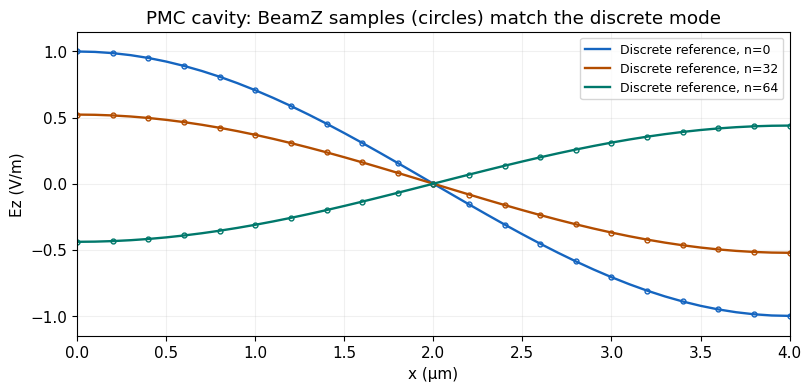

In [4]:
fig, ax = plt.subplots(layout="constrained")
for step, color in zip((0, 32, 64), ("#1565c0", "#b34d00", "#00786b")):
    ax.plot(
        x / bz.um,
        expected_ez(step)[ny // 2],
        color=color,
        linewidth=1.7,
        label=f"Discrete reference, n={step}",
    )
    ax.plot(
        x[::2] / bz.um,
        snapshots[step][ny // 2, ::2],
        "o",
        color=color,
        markersize=3.5,
        fillstyle="none",
    )
ax.set(
    xlabel="x (µm)",
    ylabel="Ez (V/m)",
    title="PMC cavity: BeamZ samples (circles) match the discrete mode",
    xlim=(0, nx * dx / bz.um),
    ylim=(-1.15, 1.15),
)
ax.grid(alpha=0.18)
ax.legend(fontsize=9, loc="upper right")
plt.show()

## Optional: a tiny 3D CUDA check
When a compatible NVIDIA device and the optional BeamZ CUDA component are available,
compare CUDA and JAX after **four timesteps on 8 × 6 × 4 cells**. This checks backend
agreement for a deterministic initial field, independently of the analytical 2D
mode above. On CPU-only machines the cell reports that CUDA was not tested.

In [5]:
from beamz.simulation.backend import cuda_backend_status

cuda_status = cuda_backend_status()
if cuda_status.available:
    tiny_3d = bz.Simulation(
        domain=(8 * dx, 6 * dx, 4 * dx),
        resolution=dx,
        time=np.arange(5) * dt,
        boundaries=[bz.PMC()],
    )
    initial_3d = tiny_3d.initial_state()
    rng = np.random.default_rng(7)
    initial_3d = initial_3d._replace(
        ez=jnp.asarray(rng.normal(size=initial_3d.ez.shape), dtype=jnp.float32)
    )
    reference = tiny_3d.advance(
        state=initial_3d, num_steps=4, backend="jax", performance=False
    ).state
    native = tiny_3d.advance(
        state=initial_3d, num_steps=4, backend="cuda_streamed", performance=False
    ).state
    for name in ("ex", "ey", "ez", "hx", "hy", "hz"):
        np.testing.assert_allclose(
            getattr(native, name), getattr(reference, name), rtol=3e-5, atol=1e-6
        )
    print("3D CUDA and JAX agree after 4 steps on 192 cells.")
else:
    print(f"CUDA execution not checked: {cuda_status.reason}")

CUDA execution not checked: JAX has no visible CUDA devices


## Next Steps
Use `bz.PMC(edges=("top", "bottom"))` to select faces, or mix wall types with
`[bz.PEC(), bz.PMC(edges="left")]`. Later specifications select the wall type on
overlapping faces. Put absorbers and reflecting walls on different faces.

Faces follow the grid axes: `left/right`, `bottom/top`, and, in 3D, `front/back`.
PMC supports JAX in 2D TM/TE and 3D, and CUDA in 3D. Rebuild the optional CUDA
component for ABI 31 before running the CUDA check.